In [5]:
import sys
sys.path.append('/home/pavel/pyadi-iio/')
sys.path.append('/home/pavel/libiio')
import adi
import matplotlib.pyplot as plt
import numpy as np

In [7]:
# Create radio
sdr = adi.ad9363("ip:192.168.2.2")
samp_rate = 20e6

'''Configure Rx properties'''
sdr.rx_enabled_channels = [0, 1]
sdr.sample_rate = int(samp_rate)
sdr.rx_rf_bandwidth = int(2e6)
sdr.rx_lo = int(2.71e9)
sdr.rx_buffer_size = 8192
sdr.gain_control_mode_chan0 = "manual"
sdr.gain_control_mode_chan1 = "manual"
sdr.rx_hardwaregain_chan0 = int(40)
sdr.rx_hardwaregain_chan1 = int(40)

In [38]:
sig = sdr.rx()

In [39]:
sig = np.asarray(sig)

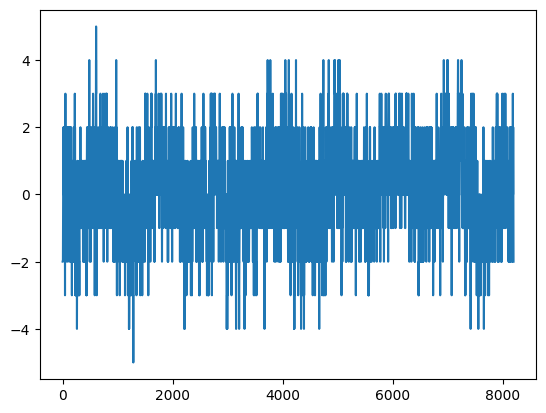

In [40]:
plt.plot(sig[0])
plt.show()

In [50]:
spec = np.fft.fft(sig[0])

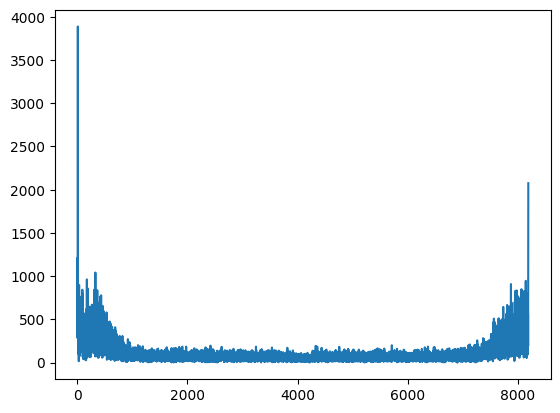

In [51]:
plt.plot(np.abs(spec))
plt.show()

In [52]:
spec[2000:6000] = 0

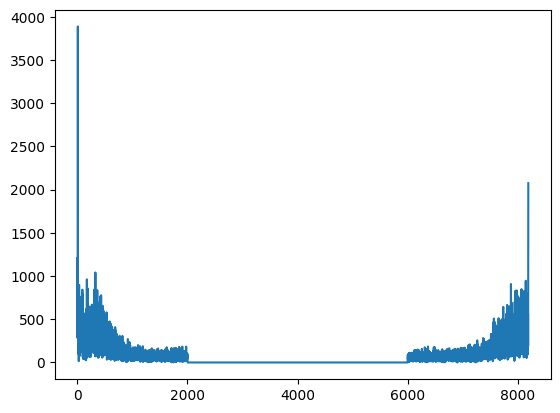

In [53]:
plt.plot(np.abs(spec))
plt.show()

In [54]:
sig_back = np.fft.ifft(spec)

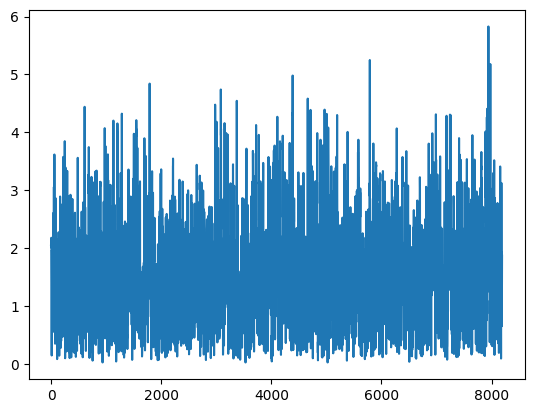

In [55]:
plt.plot(np.abs(sig_back))
plt.show()